In [1]:
import os
import sys
sys.path.insert(0, "./../../Python/test_treatments") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model


sys.path.insert(0, "./../../Python/cellular_cycle")
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4

In [3]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ './../../Python/test_treatments/parameters.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [4]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + './../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [5]:
thr = [0.26, 0.18]
return_plot = False
from Check_Model_Consistency import Check_Model_Consistency

In [7]:
variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)

2024-04-01 15:55:49.123 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [7]:
death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
for prot in death_mod:
    variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]

NameError: name 'variable_range' is not defined

In [6]:
Initial=[]
for var in list(variable_range.keys()):
    # print(variable_range[var][a])
    Initial = Initial + [int(variable_range[var][0])]

NameError: name 'variable_range' is not defined

In [8]:
Initial

[]

In [11]:
observables=['obsBAXm']

In [12]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False, seed=33); 

<Axes: xlabel='Time (h)', ylabel='Concentration'>

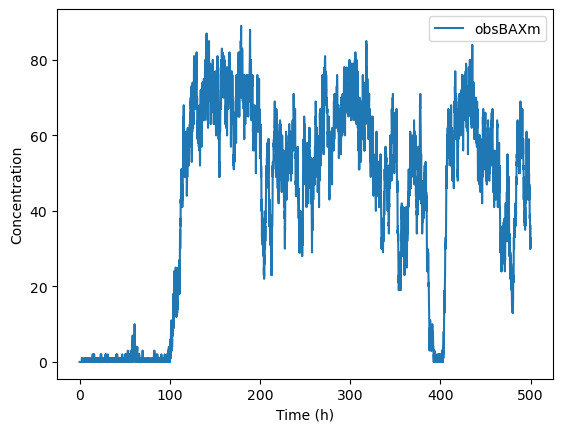

In [13]:
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,5000), legend=True)

In [16]:
death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])


In [17]:
t[death[0]]

104.9

In [15]:
from peakfinder import peakfinder

In [9]:
num_runs=10
len_runs=500
t = np.linspace(0, len_runs, len_runs*10+1)

thr = [0.26, 0.18]
return_plot = False
from Check_Model_Consistency import Check_Model_Consistency
variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
for prot in death_mod:
    variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
Initial=[]
for var in list(variable_range.keys()):
    # print(variable_range[var][a])
    Initial = Initial + [int(variable_range[var][0])]    

tot_time_death = 0
tot_time_div = len_runs*num_runs
num_dead = 0
num_divs = 0

2024-04-08 23:04:24.594 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [114]:
for ii in range(num_runs):
    sim_stoch = BngSimulator(model, tspan=t, verbose=False)
    sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
    death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
    a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
    if len(death) == 0:
        tot_time_death = tot_time_death+len_runs
    else:
        tot_time_death = tot_time_death+t[death[0]]
        num_dead+=1
    num_divs+=len(max_tmp_cdc)  

death_rate = num_dead/tot_time_death
div_rate = num_divs/tot_time_div


In [130]:
[x for x in max_tmp_cdc if x < death[0]]

[5, 225]

In [10]:
def runDeathDiv(AKT=0.3, ERK=0.2, FAK=0.4, num_runs=10, len_runs=500):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, len_runs, len_runs*10+1)
    
    thr = [0.26, 0.18]
    return_plot = False
    from Check_Model_Consistency import Check_Model_Consistency
    variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
    death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
    for prot in death_mod:
        variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
    Initial=[]
    for var in list(variable_range.keys()):
        # print(variable_range[var][a])
        Initial = Initial + [int(variable_range[var][0])]    

    tot_time_death = 0
    tot_time_div = len_runs*num_runs
    num_dead = 0
    num_divs = 0
    for ii in range(num_runs):
        sim_stoch = BngSimulator(model, tspan=t, verbose=False)
        sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
        death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
        a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
        if len(death) == 0:
            tot_time_death = tot_time_death+len_runs
        else:
            tot_time_death = tot_time_death+t[death[0]]
            num_dead+=1
        num_divs+=len(max_tmp_cdc)  
        
    death_rate = num_dead/tot_time_death
    div_rate = num_divs/tot_time_div
    return death_rate, div_rate, num_dead
            

In [11]:
def runDiv_w_Death(AKT=0.3, ERK=0.2, FAK=0.4, num_runs=10, len_runs=500):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, len_runs, len_runs*10+1)
    
    thr = [0.26, 0.18]
    return_plot = False
    from Check_Model_Consistency import Check_Model_Consistency
    variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
    death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
    for prot in death_mod:
        variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
    Initial=[]
    for var in list(variable_range.keys()):
        # print(variable_range[var][a])
        Initial = Initial + [int(variable_range[var][0])]    

    tot_time_death = 0
    tot_time_div = 0
    num_dead = 0
    num_divs = 0
    for ii in range(num_runs):
        sim_stoch = BngSimulator(model, tspan=t, verbose=False)
        sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
        death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
        a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
        
        if len(death) == 0:
            tot_time_death = tot_time_death+len_runs
            tot_time_div = tot_time_div+len_runs
            num_divs+=len(max_tmp_cdc) 
        else:
            tot_time_death = tot_time_death+t[death[0]]
            tot_time_div = tot_time_div+t[death[0]]
            num_dead+=1
            num_divs+=len([x for x in max_tmp_cdc if x < death[0]])  
        
    death_rate = num_dead/tot_time_death
    div_rate = num_divs/tot_time_div
    return death_rate, div_rate, num_dead
            

In [62]:
test, test1, num_dead = runDeathDiv(AKT=0.6, ERK=0.2, FAK=1, num_runs=100, len_runs=120)

2024-04-02 00:18:17.844 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [63]:
test

0.004374230694892324

In [64]:
test1

0.0175

In [65]:
num_dead

43

In [12]:
model.parameters['CycDi_0'].value = 0
model.parameters['V_Di'].value = 2

In [13]:
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
death_rate_di = dict([(conc, []) for conc in concs])
div_rate_di = dict([(conc, []) for conc in concs])

In [17]:
for conc in concs:
    for i in range(3):
        model.parameters['CycDi_0'].value = conc
        tmp_death, tmp_div, tmp_death_num = runDeathDiv(AKT=0.6, ERK=0.2, FAK=1, num_runs=25, len_runs=500)
        death_rate_di[conc].append(tmp_death)
        div_rate_di[conc].append(tmp_div)
    

2024-04-08 23:07:56.242 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-08 23:08:19.899 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-08 23:08:44.511 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-08 23:09:08.722 - pysb.simulator.sc

In [19]:
div_rate_di

{0: [0.03632, 0.036, 0.03656],
 0.001: [0.0364, 0.03592, 0.03672],
 0.01: [0.03264, 0.03248, 0.03192],
 0.025: [0.0268, 0.02672, 0.02584],
 0.05: [0.01784, 0.0184, 0.01904],
 0.075: [0.01392, 0.01376, 0.01344],
 0.1: [0.0116, 0.0096, 0.00992],
 0.25: [0.00064, 0.00128, 0.00168],
 0.5: [0.00024, 0.0004, 0.0],
 1: [8e-05, 8e-05, 0.0],
 2: [0.0, 0.00016, 0.0],
 5: [0.0, 0.0, 8e-05],
 10: [0.0, 0.0, 0.0]}

In [26]:
all_avgs = dict([(conc, []) for conc in concs])
for conc in concs:
    all_avgs[conc] = [1/x if x > 0 else 12500 for x in div_rate_di[conc] ]
    

In [28]:
all_avgs

{0: [27.533039647577095, 27.77777777777778, 27.35229759299781],
 0.001: [27.47252747252747, 27.839643652561247, 27.233115468409583],
 0.01: [30.637254901960784, 30.788177339901477, 31.328320802005017],
 0.025: [37.3134328358209, 37.4251497005988, 38.69969040247678],
 0.05: [56.05381165919282, 54.34782608695652, 52.52100840336134],
 0.075: [71.83908045977012, 72.67441860465117, 74.4047619047619],
 0.1: [86.20689655172414, 104.16666666666667, 100.80645161290323],
 0.25: [1562.4999999999998, 781.2499999999999, 595.2380952380952],
 0.5: [4166.666666666667, 2500.0, 12500],
 1: [12499.999999999998, 12499.999999999998, 12500],
 2: [12500, 6249.999999999999, 12500],
 5: [12500, 12500, 12499.999999999998],
 10: [12500, 12500, 12500]}

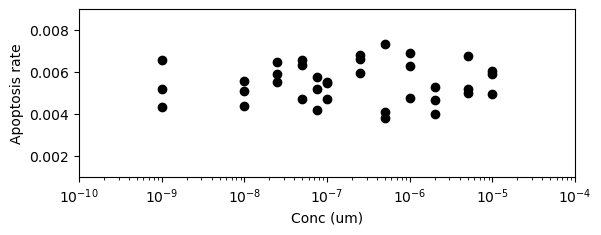

In [29]:
fig1 = plt.figure()
ax = fig1.add_subplot(2,1,1)

ax.set_xlabel('Conc (um)')
ax.set_ylabel('Apoptosis rate')
ax.set_xscale("log")
ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.009)
#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,death_rate_di[conc], color='black')

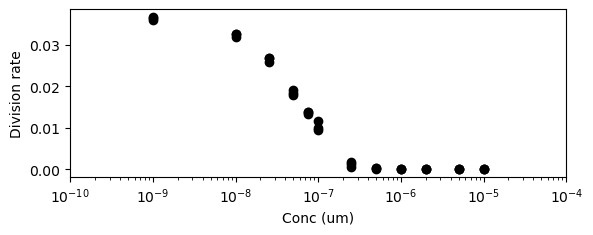

In [30]:
fig1 = plt.figure()
ax = fig1.add_subplot(2,1,1)

ax.set_xlabel('Conc (um)')
ax.set_ylabel('Division rate')
ax.set_xscale("log")
ax.set_xlim(1.0e-10, 1.0e-4)
# ax.set_ylim(0.001,0.009)
#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,div_rate_di[conc], color='black')

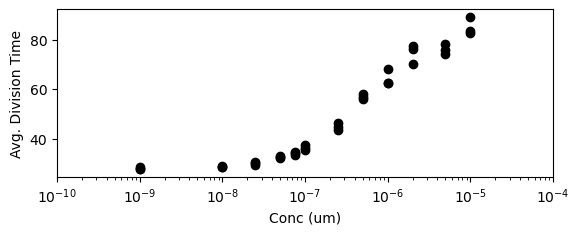

In [50]:
fig1 = plt.figure()
ax = fig1.add_subplot(2,1,1)

ax.set_xlabel('Conc (um)')
ax.set_ylabel('Avg. Division Time')
ax.set_xscale("log")
ax.set_xlim(1.0e-10, 1.0e-4)
# ax.set_ylim(0.001,0.009)
#plt.text(0,4.5,title)
all_avg_times = []
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    avg_time = [1/x for x in div_rate_di[conc]]
    all_avg_times.append(avg_time)
    ax.scatter(tmp_c,avg_time, color='black')

In [51]:
avg_times = [np.mean(x) for x in all_avg_times]

In [67]:
avg_times

[27.676119125953445,
 27.924835672324907,
 28.605421323871767,
 29.887295810720133,
 32.44326391546006,
 34.03909832489767,
 36.315209548905194,
 44.72369872508249,
 56.92042937682472,
 64.43533697632058,
 74.69466094968018,
 76.09577922077922,
 85.13350152423]

In [60]:
all_deaths = []
for time in avg_times:
    tmp_death, tmp_div, num_dead = runDeathDiv(AKT=0.6, ERK=0.2, FAK=1, num_runs=100, len_runs=int(round(time)))
    all_deaths.append(num_dead)

2024-04-02 00:05:06.570 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-02 00:06:01.043 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-02 00:06:51.219 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-04-02 00:07:45.016 - pysb.simulator.sc

In [61]:
all_deaths

[0, 0, 1, 0, 0, 1, 1, 7, 11, 23, 20, 16, 29]

In [144]:
import json

# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\death_rate_di_55kpa_erl.json', 'w') as f: 
    json.dump(death_rate_di, f)